In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("../data/processed/loans_clean.csv")
df["status"] = df["default"].map({0: "Repaid", 1: "Defaulted"})
print(df.shape)

(250000, 29)


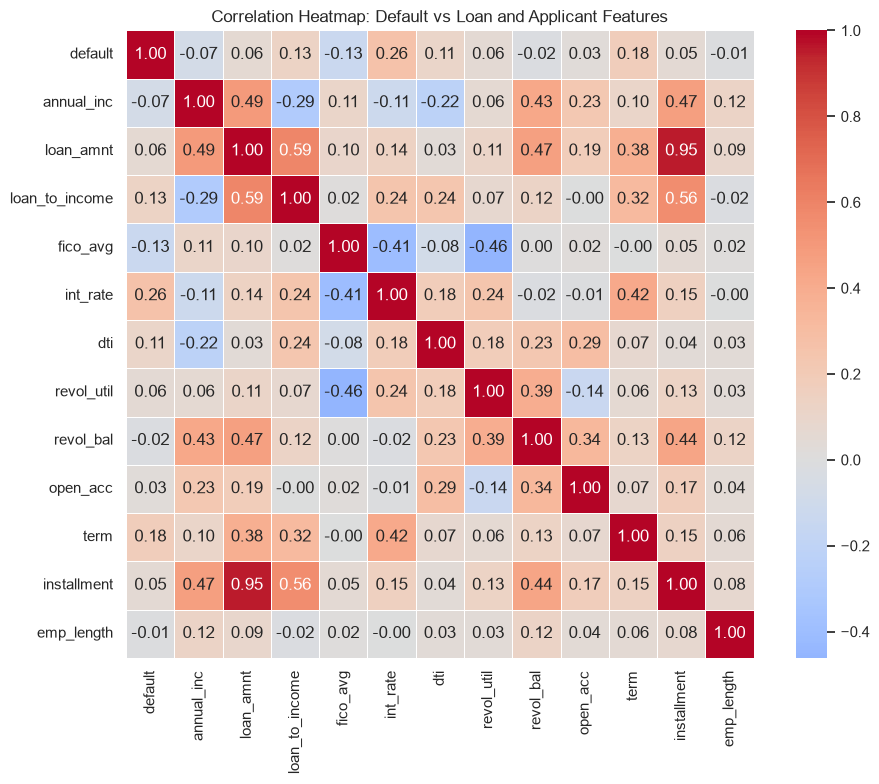

int_rate          0.259
term              0.178
fico_avg         -0.132
loan_to_income    0.129
dti               0.107
annual_inc       -0.067
loan_amnt         0.063
revol_util        0.058
installment       0.048
open_acc          0.029
revol_bal        -0.018
emp_length       -0.013
Name: default, dtype: float64


In [10]:
cols = ["default", "annual_inc", "loan_amnt", "loan_to_income", "fico_avg",
        "int_rate", "dti", "revol_util", "revol_bal", "open_acc",
        "term", "installment", "emp_length"]
corr = df[cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5)
plt.title("Correlation Heatmap: Default vs Loan and Applicant Features")
plt.tight_layout()
plt.savefig(FIG / "correlation_heatmap.png", dpi=200)
plt.show()

print(corr["default"].drop("default").sort_values(key=abs, ascending=False).round(3))

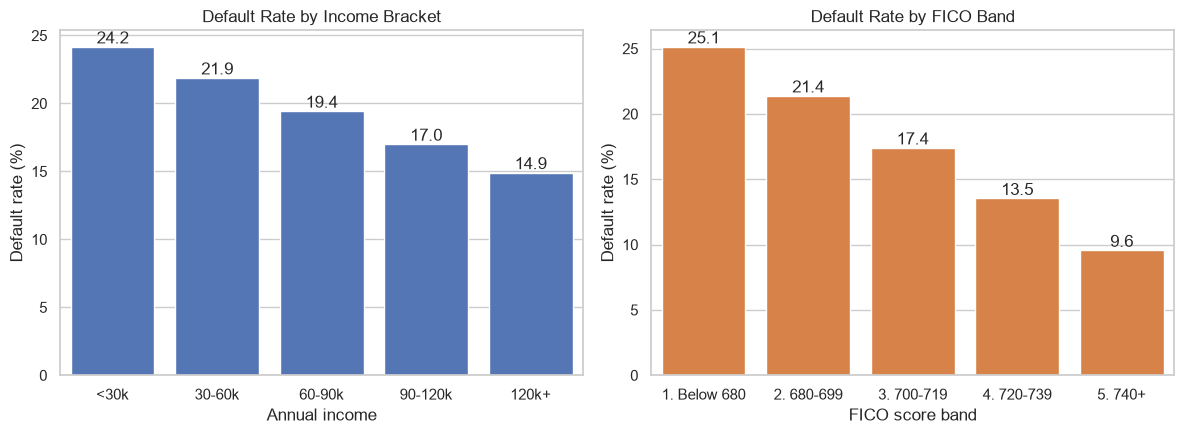

In [11]:
inc = pd.read_csv("../data/processed/default_by_income.csv")
order = ["<30k", "30-60k", "60-90k", "90-120k", "120k+"]
inc["income_bracket"] = pd.Categorical(inc["income_bracket"], order, ordered=True)
inc = inc.sort_values("income_bracket")
fico = pd.read_csv("../data/processed/default_by_fico.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=inc, x="income_bracket", y="default_rate_pct", ax=axes[0], color="#4472C4")
axes[0].set_title("Default Rate by Income Bracket")
axes[0].set_xlabel("Annual income")
sns.barplot(data=fico, x="fico_band", y="default_rate_pct", ax=axes[1], color="#ED7D31")
axes[1].set_title("Default Rate by FICO Band")
axes[1].set_xlabel("FICO score band")
for ax in axes:
    ax.set_ylabel("Default rate (%)")
    ax.bar_label(ax.containers[0], fmt="%.1f")
plt.tight_layout()
plt.savefig(FIG / "default_by_income_fico.png", dpi=200)
plt.show()

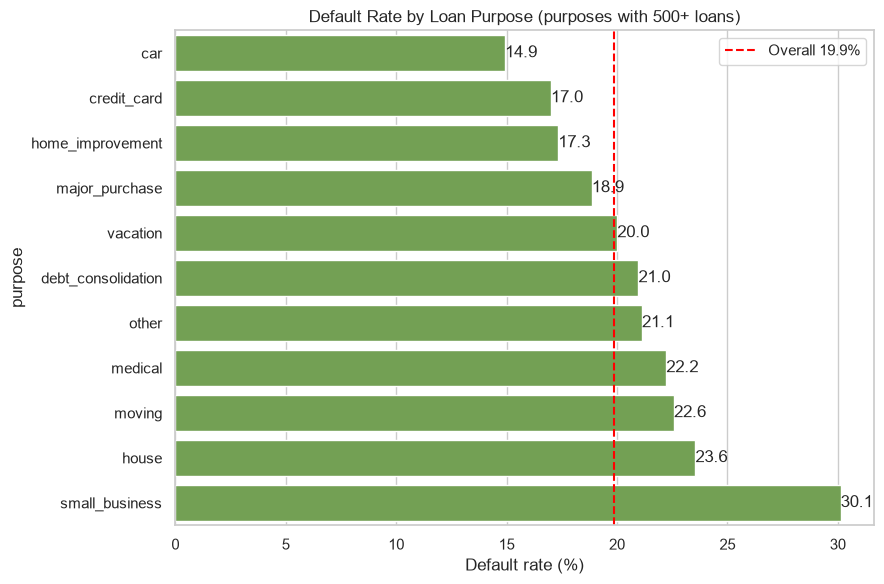

In [12]:
pur = pd.read_csv("../data/processed/default_by_purpose.csv")
pur = pur[pur["total_loans"] >= 500].sort_values("default_rate_pct")

plt.figure(figsize=(9, 6))
ax = sns.barplot(data=pur, y="purpose", x="default_rate_pct", color="#70AD47")
ax.bar_label(ax.containers[0], fmt="%.1f")
plt.axvline(19.88, color="red", linestyle="--", label="Overall 19.9%")
plt.title("Default Rate by Loan Purpose (purposes with 500+ loans)")
plt.xlabel("Default rate (%)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "default_by_purpose.png", dpi=200)
plt.show()

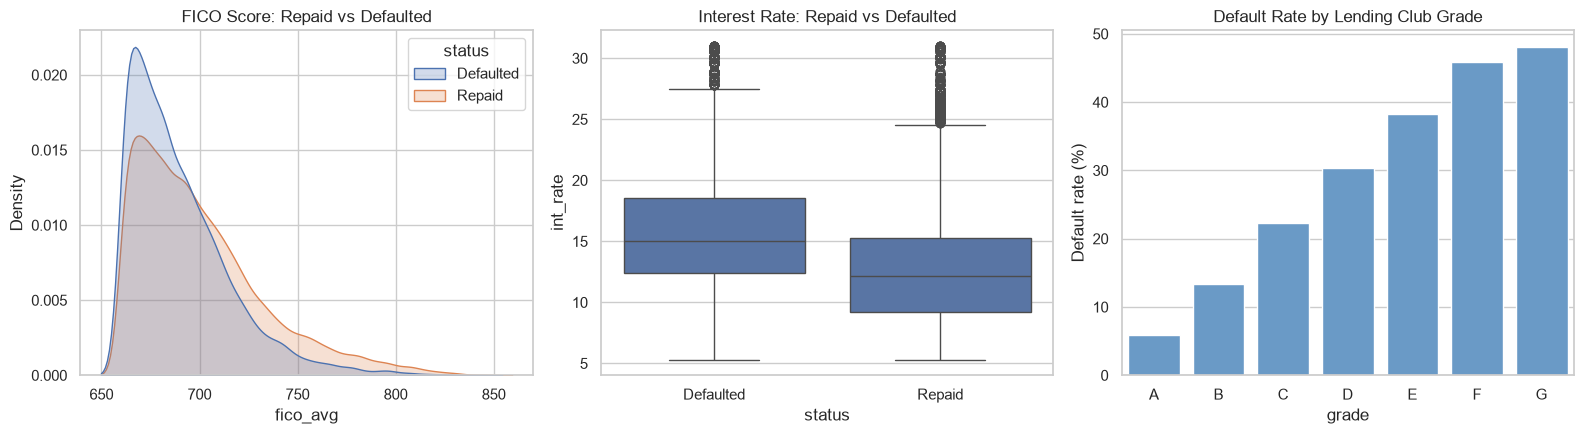

In [13]:
sample = df.sample(50000, random_state=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.kdeplot(data=sample, x="fico_avg", hue="status", common_norm=False,
            fill=True, ax=axes[0])
axes[0].set_title("FICO Score: Repaid vs Defaulted")

sns.boxplot(data=sample, x="status", y="int_rate", ax=axes[1])
axes[1].set_title("Interest Rate: Repaid vs Defaulted")

grade = df.groupby("grade")["default"].mean().mul(100).reset_index()
sns.barplot(data=grade, x="grade", y="default", ax=axes[2], color="#5B9BD5")
axes[2].set_title("Default Rate by Lending Club Grade")
axes[2].set_ylabel("Default rate (%)")

plt.tight_layout()
plt.savefig(FIG / "repaid_vs_defaulted.png", dpi=200)
plt.show()

In [14]:
print(df["annual_inc"].describe())
print(df["loan_to_income"].describe())
print("Incomes under $5,000:", (df["annual_inc"] < 5000).sum())

count    250000.000000
mean      72306.084862
std       34990.886846
min       18000.000000
25%       45850.750000
50%       65000.000000
75%       90000.000000
max      156223.875000
Name: annual_inc, dtype: float64
count    250000.000000
mean          0.216473
std           0.120976
min           0.006401
25%           0.128021
50%           0.200000
75%           0.288889
max           2.111111
Name: loan_to_income, dtype: float64
Incomes under $5,000: 0


In [15]:
print(df[["loan_to_income", "loan_amnt", "annual_inc", "default"]].corr().round(2))

diff = (df["loan_amnt"] / df["annual_inc"] - df["loan_to_income"]).abs().max()
print("Max difference vs recomputed ratio:", diff)

                loan_to_income  loan_amnt  annual_inc  default
loan_to_income            1.00       0.59       -0.29     0.13
loan_amnt                 0.59       1.00        0.49     0.06
annual_inc               -0.29       0.49        1.00    -0.07
default                   0.13       0.06       -0.07     1.00
Max difference vs recomputed ratio: 0.0
